<a href="https://colab.research.google.com/github/nisaa783/scikit-learn-cookbook_Anisa-Khasanah/blob/main/Chapter_10_Clustering_Techniques.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Pendahuluan dan Unsupervised Clustering
Clustering adalah teknik unsupervised learning yang bertujuan mengelompokkan titik-titik data ke dalam beberapa klaster (cluster) berdasarkan kemiripan karakteristiknya tanpa menggunakan label target yang sudah ditentukan sebelumnya. Titik data di dalam satu klaster diharapkan memiliki kemiripan tinggi satu sama lain (intra-cluster similarity), sedangkan titik data antar klaster yang berbeda diharapkan memiliki perbedaan yang jelas (inter-cluster dissimilarity).

Algoritma clustering banyak digunakan untuk segmentasi pelanggan, deteksi pola tersembunyi pada data eksploratif, kompresi data, hingga pengelompokan lokasi atau sensor sebelum analisis lebih lanjut.

## 2. K-Means Clustering dan Evaluasi Klaster
K-Means adalah salah satu algoritma clustering paling populer dan efisien. Algoritma ini mempartisi data ke dalam $K$ klaster dengan menetapkan setiap titik data ke centroid klaster terdekat, lalu memperbarui posisi centroid berdasarkan rata-rata anggota klaster secara iteratif hingga konvergen.Karena jumlah klaster $K$ perlu ditentukan di awal, kita sering menggunakan Elbow Method berbasis nilai Inertia (jumlah kuadrat jarak tiap titik data ke centroid klasternya) serta Silhouette Score untuk membantu memilih nilai $K$ yang masuk akal.

Konsep & Rumus Matematika:Objective Function / Inertia (Within-Cluster Sum of Squares - WCSS):$$J = \sum_{k=1}^{K} \sum_{x_i \in C_k} \vert{}\vert{}x_i - \mu_k\vert{}\vert{}^2$$di mana $C_k$ adalah himpunan titik data pada klaster ke-$k$ dan $\mu_k$ adalah titik pusat (centroid) klaster ke-$k$.Silhouette Coefficient untuk suatu sampel $i$:$$s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}$$dengan $a(i)$ sebagai rata-rata jarak sampel $i$ ke titik lain dalam klaster yang sama, dan $b(i)$ sebagai rata-rata jarak terkecil sampel $i$ ke seluruh titik di klaster lain terdekat. Nilai berada di rentang $[-1, 1]$, di mana nilai mendekati $1$ menunjukkan pengelompokan yang terpisah dengan baik.

## 3. Contoh Program Penerapan 1: K-Means Clustering dan Analisis Inertia (Elbow Method)
Contoh program pertama ini membangun data sintetis berbentuk klaster, menerapkan KMeans, serta menghitung nilai inertia_ untuk berbagai nilai $K$ guna mengamati titik siku (elbow).



Koordinat Centroid (K=4):
[[-2.645  8.984]
 [-6.839 -6.838]
 [ 4.706  2.032]
 [-8.833  7.211]]
Nilai Inertia (K=4): 409.1974
Distribusi anggota tiap klaster: {np.int32(0): np.int64(75), np.int32(1): np.int64(75), np.int32(2): np.int64(75), np.int32(3): np.int64(75)}
K=1 -> Inertia: 19819.35
K=2 -> Inertia: 9258.19
K=3 -> Inertia: 1962.87
K=4 -> Inertia: 409.20
K=5 -> Inertia: 370.09
K=6 -> Inertia: 332.58
K=7 -> Inertia: 295.28
K=8 -> Inertia: 262.85


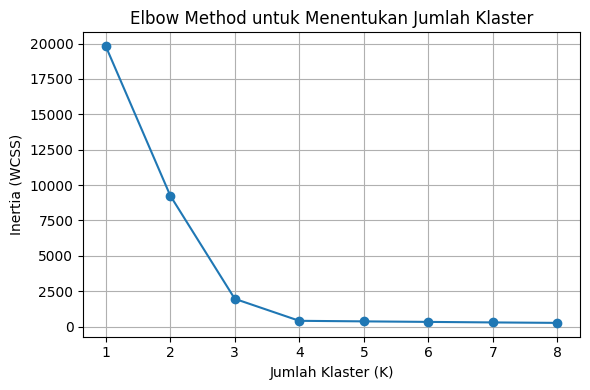

In [1]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs

# 1. Membuat dataset sintetis dengan 4 kelompok klaster
X, _ = make_blobs(
    n_samples=300,
    centers=4,
    cluster_std=0.85,
    random_state=42
)

# 2. Melatih K-Means dengan K=4
kmeans = KMeans(n_clusters=4, n_init=10, random_state=42)
clusters = kmeans.fit_predict(X)

print(f"Koordinat Centroid (K=4):\n{kmeans.cluster_centers_.round(3)}")
print(f"Nilai Inertia (K=4): {kmeans.inertia_:.4f}")
print(f"Distribusi anggota tiap klaster: {dict(zip(*__import__('numpy').unique(clusters, return_counts=True)))}")

# 3. Menghitung Inertia untuk K=1 hingga K=8 (Elbow Method)
inertias = []
k_values = range(1, 9)

for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X)
    inertias.append(km.inertia_)

for k, val in zip(k_values, inertias):
    print(f"K={k} -> Inertia: {val:.2f}")

# 4. Visualisasi Elbow Curve
plt.figure(figsize=(6, 4))
plt.plot(list(k_values), inertias, marker='o')
plt.title("Elbow Method untuk Menentukan Jumlah Klaster")
plt.xlabel("Jumlah Klaster (K)")
plt.ylabel("Inertia (WCSS)")
plt.grid(True)
plt.tight_layout()
plt.show()

## 4. Contoh Program Penerapan 2: Penskalaan Fitur dan Evaluasi Silhouette Score pada K-Means

Karena K-Means berbasis jarak Euclidean, perbedaan skala antar fitur dapat mendistorsi pembentukan klaster. Contoh kedua ini menggabungkan StandardScaler dengan KMeans pada dataset load_iris dan mengevaluasi kualitas klaster menggunakan silhouette_score.



In [2]:
from sklearn.cluster import KMeans
from sklearn.datasets import load_iris
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# 1. Memuat dataset Iris (tanpa menggunakan label target saat clustering)
iris = load_iris()
X = iris.data

# 2. Menstandarkan skala fitur agar tiap variabel berkontribusi seimbang
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Menguji beberapa nilai K dan menghitung Silhouette Score
for k in [2, 3, 4, 5]:
    model = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    print(f"K={k} | Inertia: {model.inertia_:.2f} | Silhouette Score: {score:.4f}")

K=2 | Inertia: 222.36 | Silhouette Score: 0.5818
K=3 | Inertia: 139.82 | Silhouette Score: 0.4599
K=4 | Inertia: 114.09 | Silhouette Score: 0.3869
K=5 | Inertia: 90.93 | Silhouette Score: 0.3459
